In [16]:
import os
import sys

import joblib
import itertools
import pandas as pd
import numpy as np
from sklearn.svm import OneClassSVM

sys.path.insert(0, '../../..') 
from utils.helper_functions import normalize_series
from utils.plotting import plot_movement_data
from utils.constants import Configs
from utils.loso_models.ocsvm_detector import OCSVMDetector
from utils.loso_pipeline import run_loso_evaluation
from utils.metrics import show_feature_extraction_metrics
from utils.helper_functions import calculate_matrix_trash_percentage
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.dtw_radius import load_dtw_matrices

TARGET_MOVEMENT = 'Move'
ALGORITHM_NAME = 'OCSVM'
MODEL_REPRESENTATION = 'ShapeBased'

EXTRACT_SCORES = True

In [17]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [18]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID', 'movID'])
total_known_outliers = len(outliers_csv)

# Filter the outliers for the target movement
outliers_csv = outliers_csv[outliers_csv['movLabel'] == TARGET_MOVEMENT].reset_index(drop=True)
total_target_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
print(f"Total target outliers: {total_target_outliers}")
outliers_csv.head()

Total known outliers: 18
Total target outliers: 5


,sub,repID,movID,movLabel
0,2,2,9,Move
1,4,1,9,Move
2,7,1,9,Move
3,11,1,9,Move
4,12,1,9,Move


In [19]:
# Making sure that the metadata is perfectly aligned with the movement data matrix (X_movement)
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

group_array = ['x', 'y', 'z']
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 2776.97it/s]

Shape of first series: (72, 3)
Shape of formatted series: (95, 196, 3)


## One Class SVM

In [20]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().reset_index(drop=True)

total_samples = len(results_temp_base)                                  
total_trials  = len(df_filtered[['sub', 'repID']].drop_duplicates())
known_outlier_rate = (total_target_outliers / total_samples) if total_samples > 0 else 0.0
percentagem_conhecida = known_outlier_rate * 100


if total_samples != X_movement.shape[0]:
    raise ValueError(
        f"⚠️ CRITICAL ERROR: Metadata ({total_samples}) does not match "
        f"the matrix ({X_movement.shape[0]})!"
    )

print(
    f"✅ Perfect synchronization! Matrix rows: {X_movement.shape[0]} | "
    f"Metadata rows: {total_samples}"
)
print(f"Total samples in the matrix: {total_samples}")
print(f"Total unique repetitions analyzed ({TARGET_MOVEMENT}): {total_trials}")
print(
    f"Minimum confirmed outlier rate from the CSV "
    f"(Subject + RepID + movID): {percentagem_conhecida:.2f}%"
)

✅ Perfect synchronization! Matrix rows: 95 | Metadata rows: 95
Total samples in the matrix: 95
Total unique repetitions analyzed (Move): 95
Minimum confirmed outlier rate from the CSV (Subject + RepID + movID): 5.26%


### Grid Search

In [21]:
nu_range = [0.01, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
gamma_multipliers = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]

param_grid = [{'nu': n, 'gamma_scale': g}
              for n, g in itertools.product(nu_range, gamma_multipliers)]

matrices = load_dtw_matrices(TARGET_MOVEMENT, Configs.DTW_RADIUS_Seconds, Configs.wrist_only_constrained_dtw_distance_matrix)

loso_results = run_loso_evaluation(
    detector_class=OCSVMDetector, 
    param_grid=param_grid,
    data_matrix=next(iter(matrices.values())),   # placeholder, replaced per fold
    metadata_df=results_temp_base,
    known_outliers_df=outliers_csv,
    metric_type='precomputed',
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    dtw_matrices=matrices # Gamma prepared for each fold based on the DTW distance matrix
)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

print("\nSearch Results:")
print("Teste", f"MCC={loso_results['MCC']:.3f}", f"Rej={loso_results['Rejection_Rate']:.1f}%",
          f"AUROC={loso_results['AUROC']:.3f}")

LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 
Search Results:
Teste MCC=0.217 Rej=35.8% AUROC=0.747


If most of the Off-diagonal values are lesser thatn 0.01, the kernel has collapsed.

### Statistic Evaluation (TRIAL-LEVEL) - Bootstraping

In [22]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [23]:
append_experiment_record(
    summary_path=Configs.WRIST_ONLY_CSV_SHAPE_BASED_SUMMARY_FILE,
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=total_samples,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for OCSVM - ShapeBased - Move - 95 Movements (MOVEMENT-level):
Unique Outliers Detected: 34
Rejection Rate: 35.79%
Known Positives in Ground Truth: 5
------------------------------
Total True Positives (Global):  4
Total False Positives (Global): 30
Total False Negatives (Global): 1
Total True Negatives (Global):  60
------------------------------
Blind Precision: 11.76 [2.62–25.71]
Blind Recall:    80.00 [33.33–100.00]
Blind F1-Score:  20.51
Blind F2-Score:  37.04 [10.64–60.25]
Blind MCC:       0.22 [-0.00–0.42]
Blind AUPRC:  34.44 [4.66–79.22]
Blind AUROC:   74.67

Total Tuning Time (19 Subjects): 5.2284s
Total Inference Time (19 Subjects): 0.0157s

Overall Best Parameters (Most frequent across folds):
   {'gamma_scale': 1.0, 'nu': 0.15}
Occurrences: 5


### Train Model

In [24]:
# Recalculating the Kernel Matrix with the Winning Gamma
best_params = loso_results['Best_Params']
best_gamma = best_params['gamma_scale']
best_nu = best_params['nu']

selected_radius = loso_results['Most_Frequent_DTW_Radius']
selected_dtw_matrix = matrices[selected_radius]      # `matrices` is the dict loaded earlier
best_kernel_matrix = np.exp(-best_gamma * selected_dtw_matrix)

In [25]:
off_diag = best_kernel_matrix[~np.eye(len(best_kernel_matrix), dtype=bool)]
print(f"Off‑diagonal kernel stats: min={off_diag.min():.6f}, "
      f"max={off_diag.max():.6f}, median={np.median(off_diag):.6f}")

Off‑diagonal kernel stats: min=0.000000, max=0.000000, median=0.000000


In [26]:
# Train One-Class SVM on the DTW distance matrix
# kernel = 'precomputed' means that we are providing a distance matrix instead of raw features
# nu=0.05 means that we expect that 5% of the data are outliers (adjust as needed) 0.05 is a common starting value (with 0.01 performed better, idk why)
ocsvm_model = OneClassSVM(nu=best_nu, gamma=best_gamma, kernel='precomputed') # since the kernel is precomputed, I do not need to pass the gamma parameter
labels = ocsvm_model.fit_predict(best_kernel_matrix)
joblib.dump(ocsvm_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

outlier_indices = np.where(labels == -1)[0]
n_outliers = len(outlier_indices)

In [27]:
# Reconstruct metadata for cross-referencing with the original CSV
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

n_unique_outliers, correct_trash_pct = calculate_matrix_trash_percentage(outlier_indices, metadata_df)

X_movement_clean = np.delete(X_movement, outlier_indices, axis=0) # shape (n_samples - n_outliers, T, n_features)
X_movement_outliers = X_movement[outlier_indices] # shape (n_outliers, T, n_features)

print(f"Raw Outlier Trials Detected: {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Detected Outlier Percentage (sub + repID + movID): {(n_outliers / total_trials * 100):.2f}%")
print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 38
Unique Outlier Trials Detected: 38
Detected Outlier Percentage (sub + repID + movID): 40.00%
Detected Outlier Percentage (sub + repID): 40.00%


In [28]:
real_outliers_info = metadata_df.iloc[outlier_indices][["sub", "repID", "movID", "movLabel"]]
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

print("Outlier Details:")
print(real_outliers_info)

Outlier Details:
    sub  repID  movID movLabel
14    3      5      9     Move
15    4      1      9     Move
16    4      2      9     Move
17    4      3      9     Move
18    4      4      9     Move
19    4      5      9     Move
20    5      1      9     Move
21    5      2      9     Move
22    5      3      9     Move
23    5      4      9     Move
24    5      5      9     Move
25    6      1      9     Move
37    8      3      9     Move
38    8      4      9     Move
39    8      5      9     Move
40    9      1      9     Move
51   11      2      9     Move
74   15      5      9     Move
75   16      1      9     Move
76   16      2      9     Move
77   16      3      9     Move
78   16      4      9     Move
79   16      5      9     Move
80   17      1      9     Move
81   17      2      9     Move
82   17      3      9     Move
83   17      4      9     Move
84   17      5      9     Move
85   18      1      9     Move
86   18      2      9     Move
87   18      3      9 

In [29]:
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = show_feature_extraction_metrics(
    metadata_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 1
False Positives (Identified, not in CSV): 37
False Negatives (In CSV, not identified): 4
True Negatives (Normal, stayed normal): 53
--------------------------------------------------
Missing outliers (In CSV, not identified):
   sub  repID
0    2      2
2    7      1
3   11      1
4   12      1

Precision (False Positives): 1/38 (2.63%)
Recall (True Positive Rate): 1/5 (20.00%)
F1-Score: 4.65%
F2-Score: 8.62%


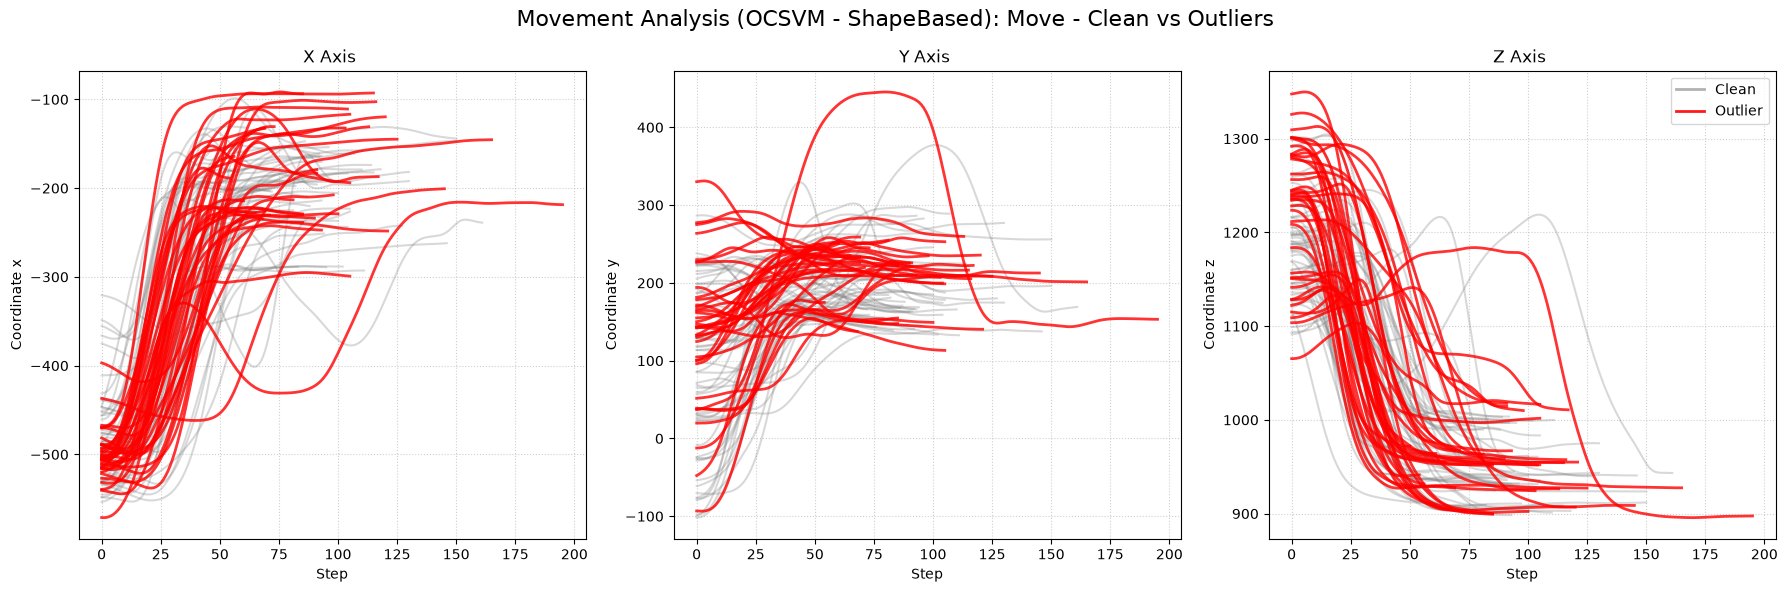

In [30]:
plot_movement_data(
    clean_data=X_movement_clean,
    outlier_data=X_movement_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)